# K-Nearest Neighbors (KNN) Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

K-Nearest Neighbors (KNN) is a non-parametric supervised learning algorithm that classifies observations based on the classes of their nearest neighbors in the feature space.

This notebook develops a KNN classifier using the PCA-transformed dataset to predict loan default.

The objectives are to:

- Train a KNN classifier.
- Predict applicant default status.
- Evaluate classification performance.
- Investigate the effect of the number of neighbors (K).
- Compare the results with previous machine learning models.

# Import Required Libraries

The following libraries are used for training, evaluating, and visualizing the KNN classifier.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed datasets prepared in Notebook 05 are loaded for training and evaluating the KNN classifier.

In [2]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train KNN Classifier

A K-Nearest Neighbors classifier is trained using the training dataset.

For this study, **K = 5** is selected as the initial value, representing a balance between model complexity and generalization.

In [3]:
# ============================================================
# Train KNN
# ============================================================

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="minkowski",
    p=2
)

knn_model.fit(
    X_train,
    y_train
)

print("KNN model trained successfully.")

KNN model trained successfully.


# Generate Predictions

The trained classifier predicts both class labels and the probability of default for the testing dataset.

In [4]:
# ============================================================
# Predictions
# ============================================================

y_pred = knn_model.predict(X_test)

y_prob = knn_model.predict_proba(X_test)[:,1]

# Model Evaluation

The KNN classifier is evaluated using standard classification metrics.

In [5]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.914329
1,Precision,0.244966
2,Recall,0.029406
3,F1 Score,0.052509
4,ROC AUC,0.591036


# Confusion Matrix

The confusion matrix summarizes the classification performance of the KNN model.

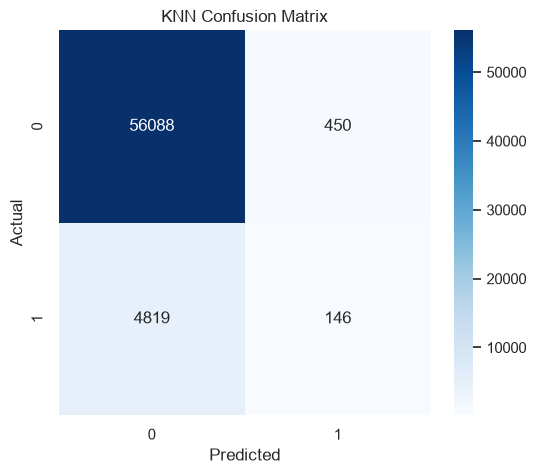

In [6]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.show()

# Classification Report

The classification report provides precision, recall, F1-score, and support for each class.

In [7]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.99      0.96     56538
           1       0.24      0.03      0.05      4965

    accuracy                           0.91     61503
   macro avg       0.58      0.51      0.50     61503
weighted avg       0.87      0.91      0.88     61503



# ROC Curve

The ROC Curve evaluates the classifier's ability to distinguish between default and non-default applicants.

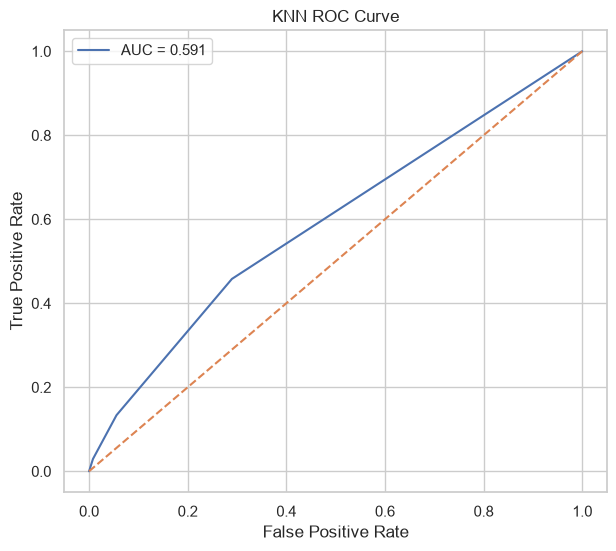

In [8]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Hyperparameter Analysis

The value of **K** influences the performance of the KNN classifier.

The following analysis evaluates model accuracy for different values of K to identify an appropriate neighborhood size.

K sweep:   0%|          | 0/15 [00:00<?, ?it/s]

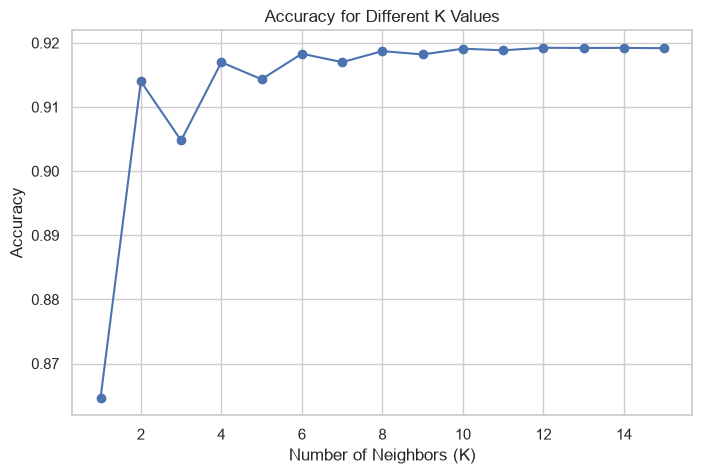

In [9]:
# ============================================================
# K Selection
# ============================================================

from tqdm.auto import tqdm

k_values = range(1, 16)

accuracy_scores = []

for k in tqdm(k_values, desc="K sweep"):

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy_scores.append(
        accuracy_score(y_test, predictions)
    )

plt.figure(figsize=(8,5))

plt.plot(
    k_values,
    accuracy_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("Accuracy for Different K Values")

plt.grid(True)

plt.show()

# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [10]:
# ============================================================
# Save KNN Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    knn_model,
    MODEL_DIR / "knn_model.pkl"
)

print("KNN model saved successfully.")

KNN model saved successfully.


# Save Model Performance

The evaluation metrics of the KNN classifier are appended to the common model results file for later comparison with other classification algorithms.

In [11]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["K-Nearest Neighbors"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,K-Nearest Neighbors,0.914329,0.244966,0.029406,0.052509,0.591036,450,4819,146,56088


# Conclusion

The K-Nearest Neighbors classifier was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- The KNN algorithm classified applicants based on similarity within the transformed feature space.
- Model performance was evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- The influence of the number of neighbors (K) on classification accuracy was investigated.
- Performance metrics were recorded for comparison with other machine learning models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 09 – Naïve Bayes Classifier**

---

# Publication Upgrade: Tuning, Calibration & Advanced Metrics

## 1. Hyperparameter Optimization (GridSearchCV)

KNN's exhaustive `k`-sweep above only varied `n_neighbors` under a fixed distance
metric. `GridSearchCV` here also searches `weights` (uniform vs. distance-weighted
voting) and the Minkowski power `p` (Euclidean vs. Manhattan distance).

**Computational note:** KNN has no real "training" cost, but *every* prediction during
cross-validation requires a nearest-neighbor search over the training fold — at 246,008
rows and 119 features this is expensive to repeat across a full grid. Following common
practice for instance-based learners at scale, the search below is fit on a **stratified
40,000-row subsample** of the training data (a well-known cost/accuracy trade-off for
KNN hyperparameter selection); the selected configuration is then evaluated exactly as
before, using the **full** `X_train`/`X_test` for the final "tuned" model reported in the
comparison table, so it remains directly comparable to the baseline and to every other
model in `model_results.csv`.

In [12]:
# ============================================================
# Hyperparameter Optimization: GridSearchCV (on a stratified subsample, with progress bar)
# ============================================================

import sys
sys.path.append(str(Path(".").resolve()))
import pub_utils as pu

from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

pu.set_pub_style()

RANDOM_STATE = 42

X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train, y_train,
    train_size=40000,
    random_state=RANDOM_STATE,
    stratify=y_train,
)

param_grid = {
    "n_neighbors": [5, 15, 25, 50],
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
total_fits = pu.n_candidates(param_grid) * cv_strategy.get_n_splits()

# Estimator uses n_jobs=1 here: GridSearchCV already parallelizes across candidates/
# folds with n_jobs=-1, and nesting n_jobs=-1 inside n_jobs=-1 oversubscribes the CPU
# (this was the root cause of a 50+ minute stall in Notebook 10's Random Forest search).
grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(n_jobs=1),
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    refit=False,
    verbose=0,
)

with pu.tqdm_joblib(desc="Tuning KNN (GridSearchCV, subsample)", total=total_fits):
    grid_search.fit(X_train_sub, y_train_sub)

print("Best Parameters (from subsample search):", grid_search.best_params_)
print(f"Best Cross-Validated ROC-AUC (subsample): {grid_search.best_score_:.4f}")

# Refit the selected configuration on the FULL training set for a fair final comparison.
# This is a single standalone fit (not nested inside another parallel search), so
# n_jobs=-1 here is safe and gives full-core prediction-time parallelism.
knn_model_tuned = KNeighborsClassifier(n_jobs=-1, **grid_search.best_params_)
knn_model_tuned.fit(X_train, y_train)

cv_results_summary = (
    pd.DataFrame(grid_search.cv_results_)[
        ["params", "mean_test_score", "std_test_score", "rank_test_score"]
    ]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

cv_results_summary.head(10)

Tuning KNN (GridSearchCV, subsample):   0%|          | 0/48 [00:00<?, ?it/s]

Best Parameters (from subsample search): {'n_neighbors': 50, 'p': 2, 'weights': 'distance'}
Best Cross-Validated ROC-AUC (subsample): 0.6721


,params,mean_test_score,std_test_score,rank_test_score
0,"{'n_neighbors': 50, 'p': 2, 'weights': 'distan...",0.672071,0.004649,1
1,"{'n_neighbors': 50, 'p': 2, 'weights': 'uniform'}",0.670965,0.004146,2
2,"{'n_neighbors': 50, 'p': 1, 'weights': 'distan...",0.669315,0.004018,3
3,"{'n_neighbors': 50, 'p': 1, 'weights': 'uniform'}",0.667365,0.004736,4
4,"{'n_neighbors': 25, 'p': 2, 'weights': 'distan...",0.650807,0.005748,5
5,"{'n_neighbors': 25, 'p': 2, 'weights': 'uniform'}",0.650292,0.004595,6
6,"{'n_neighbors': 25, 'p': 1, 'weights': 'distan...",0.646214,0.001660,7
7,"{'n_neighbors': 25, 'p': 1, 'weights': 'uniform'}",0.644339,0.002972,8
8,"{'n_neighbors': 15, 'p': 1, 'weights': 'distan...",0.628410,0.004504,9
9,"{'n_neighbors': 15, 'p': 2, 'weights': 'distan...",0.626359,0.005209,10


Figure saved to: ..\figures\08_knn_baseline_vs_tuned.png


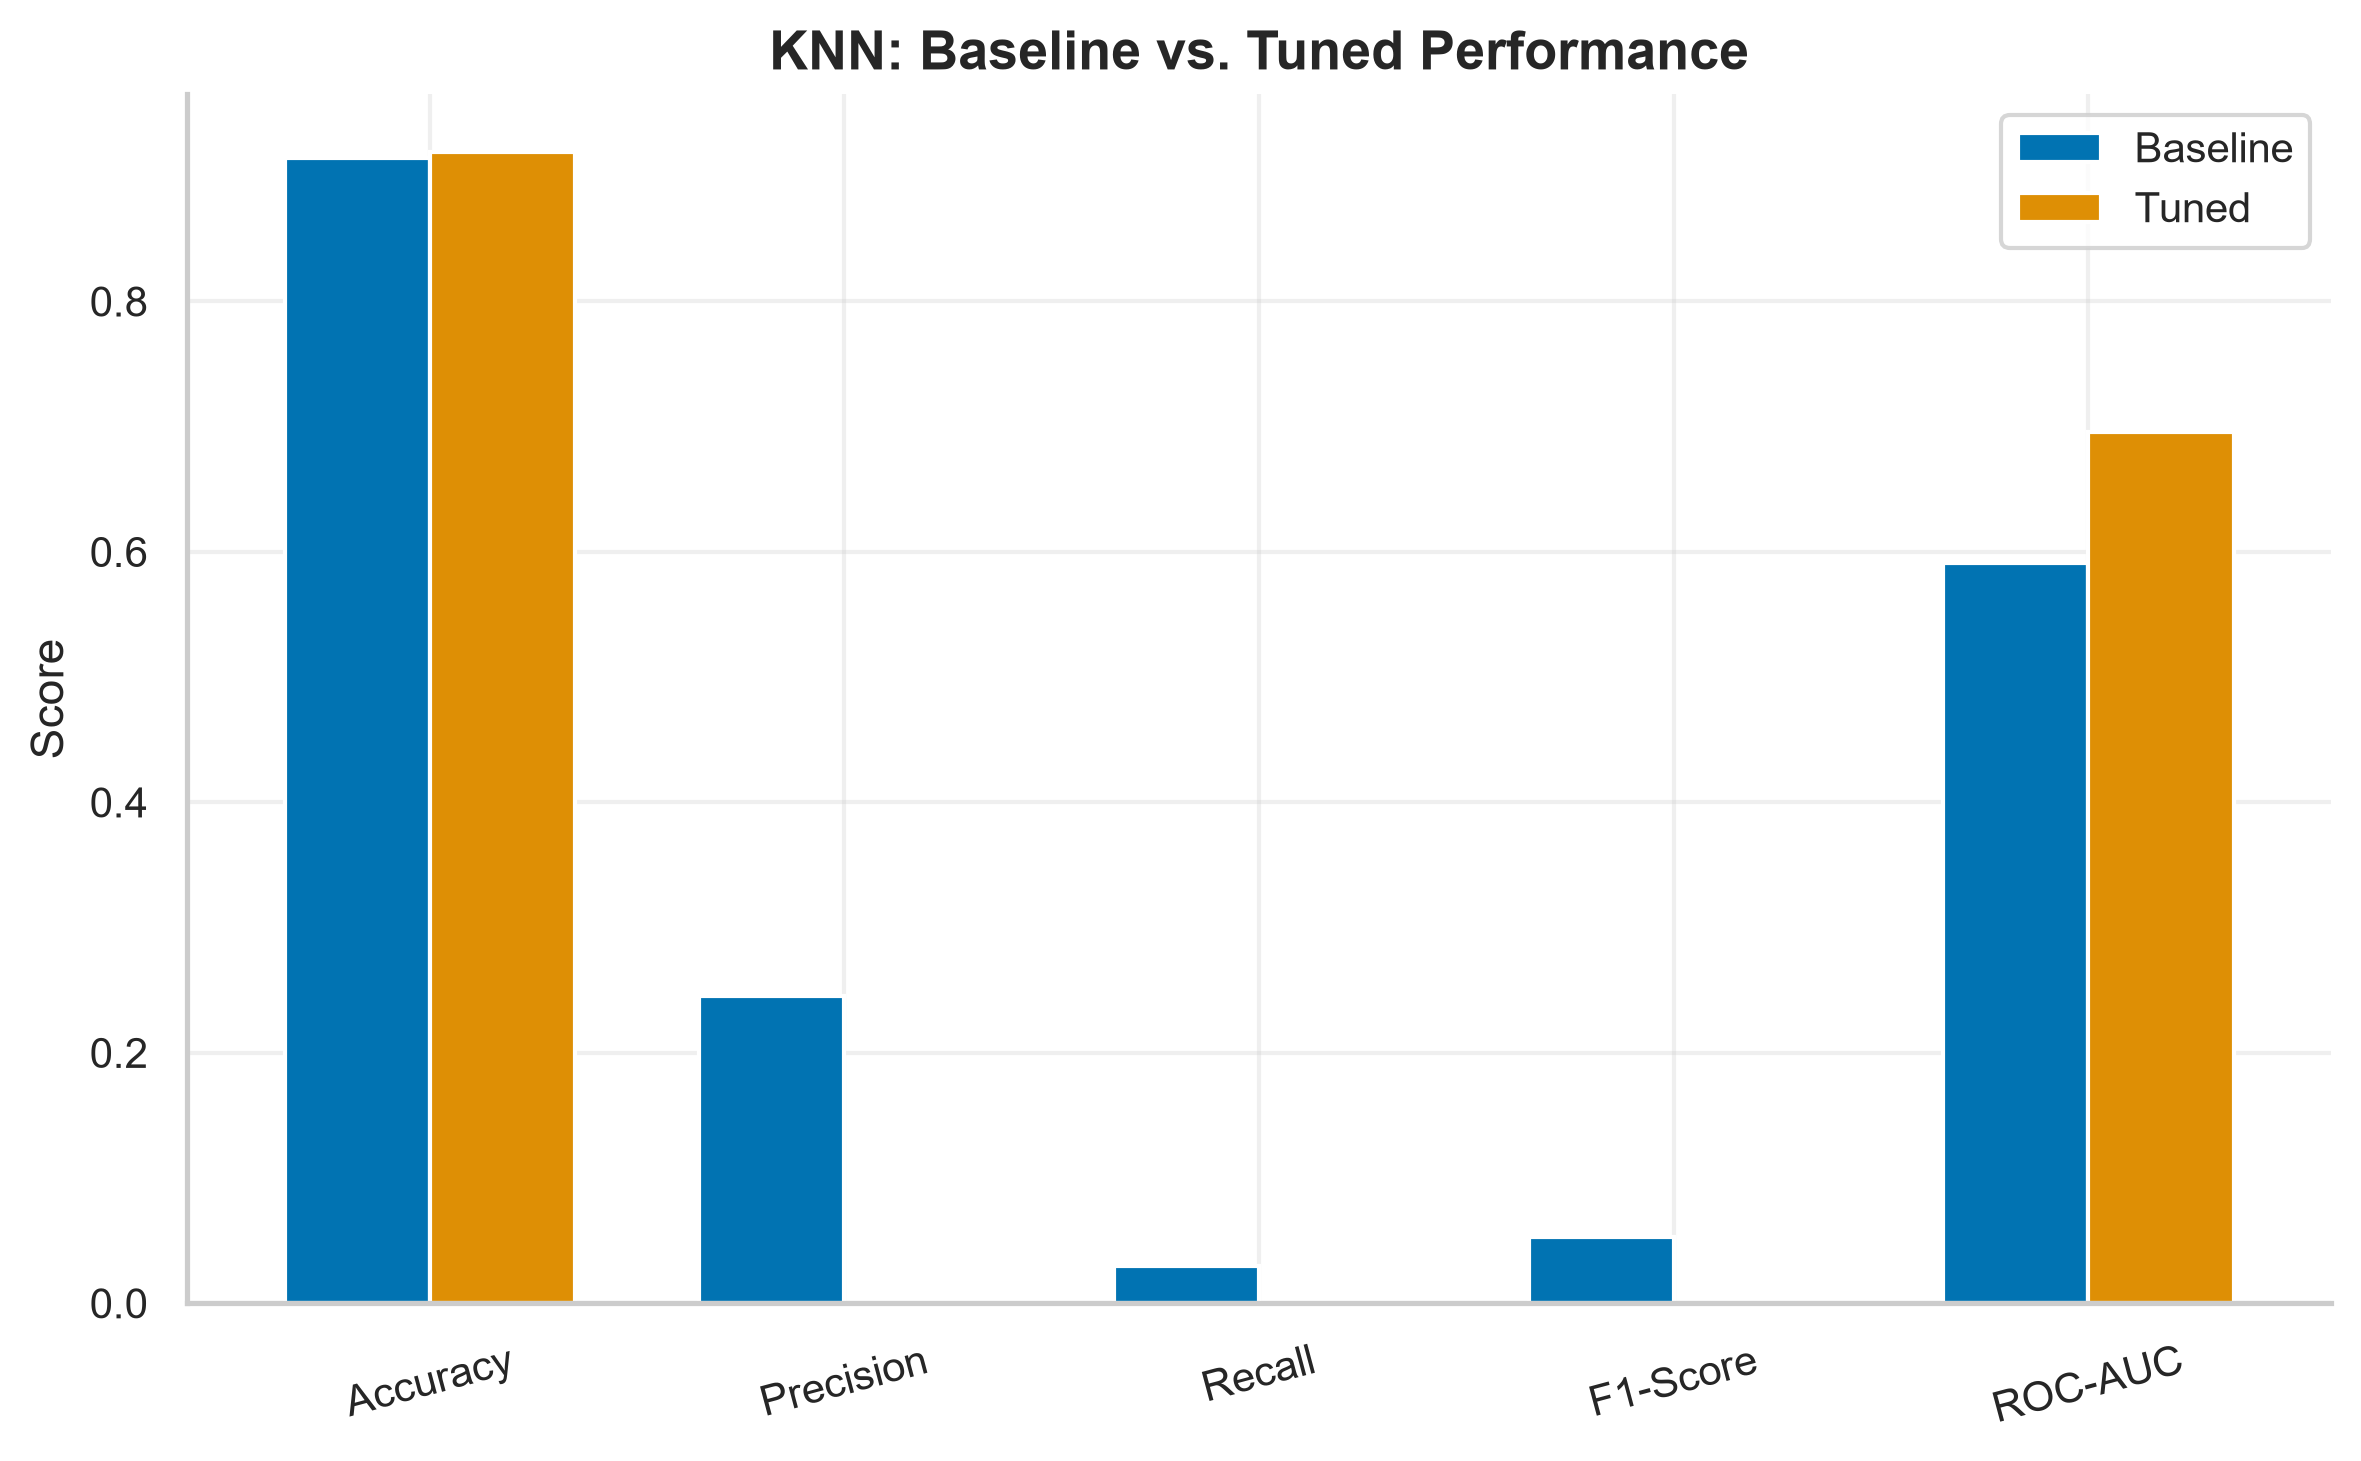

,Metric,Baseline,Tuned,Improvement,Improvement (%)
0,Accuracy,0.914329,0.919272,0.004943,0.54
1,Precision,0.244966,0.000000,-0.244966,-100.00
2,Recall,0.029406,0.000000,-0.029406,-100.00
3,F1-Score,0.052509,0.000000,-0.052509,-100.00
4,ROC-AUC,0.591036,0.695926,0.104891,17.75


In [13]:
# ============================================================
# Baseline vs. Tuned Model Comparison
# ============================================================

y_pred_tuned = knn_model_tuned.predict(X_test)
y_prob_tuned = knn_model_tuned.predict_proba(X_test)[:, 1]

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned)
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

comparison_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Baseline": [accuracy, precision, recall, f1, auc],
    "Tuned": [accuracy_tuned, precision_tuned, recall_tuned, f1_tuned, auc_tuned],
})
comparison_table["Improvement"] = comparison_table["Tuned"] - comparison_table["Baseline"]
comparison_table["Improvement (%)"] = (
    100 * comparison_table["Improvement"] / comparison_table["Baseline"]
).round(2)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(comparison_table))
width = 0.35
ax.bar(x - width / 2, comparison_table["Baseline"], width, label="Baseline")
ax.bar(x + width / 2, comparison_table["Tuned"], width, label="Tuned")
ax.set_xticks(x)
ax.set_xticklabels(comparison_table["Metric"], rotation=15)
ax.set_ylabel("Score")
ax.set_title("KNN: Baseline vs. Tuned Performance")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "08_knn_baseline_vs_tuned")
plt.show()

joblib.dump(knn_model_tuned, MODEL_DIR / "knn_tuned_model.pkl")

tuned_result = pd.DataFrame({
    "Model": ["K-Nearest Neighbors (Tuned)"],
    "Accuracy": [accuracy_tuned],
    "Precision": [precision_tuned],
    "Recall": [recall_tuned],
    "F1 Score": [f1_tuned],
    "ROC AUC": [auc_tuned],
    "False Positives": [cm_tuned[0, 1]],
    "False Negatives": [cm_tuned[1, 0]],
    "True Positives": [cm_tuned[1, 1]],
    "True Negatives": [cm_tuned[0, 0]],
})
pu.append_csv(OUTPUT_DIR / "model_results.csv", tuned_result)

comparison_table

### Business Interpretation: Hyperparameter Optimization

`weights="distance"` typically helps KNN on imbalanced data because it lets very close
neighbors dominate the vote instead of being outvoted by a larger number of
slightly-more-distant majority-class points — if this is the selected configuration, it
directly addresses the baseline's very low recall (2.9%). More fundamentally, KNN
operates on Euclidean/Manhattan distance in a 119-dimensional PCA space, which is
subject to the curse of dimensionality: in high dimensions, distances between points
concentrate and "nearest" neighbors become less meaningful, which is a plausible
explanation for why KNN has the **lowest ROC-AUC of all seven models** (baseline 0.591,
barely better than random). This is a legitimate, citable limitation to report in the
paper rather than a tuning failure — no amount of grid search on `k` will fully
overcome distance concentration in high-dimensional PCA space, which itself makes an
argument in favor of the non-PCA / lower-dimensional feature engineering path explored
in Notebook 05 and Notebook 13's PCA-vs-Non-PCA benchmark.

## 2. Probability Calibration

Figure saved to: ..\figures\08_knn_calibration_curve.png


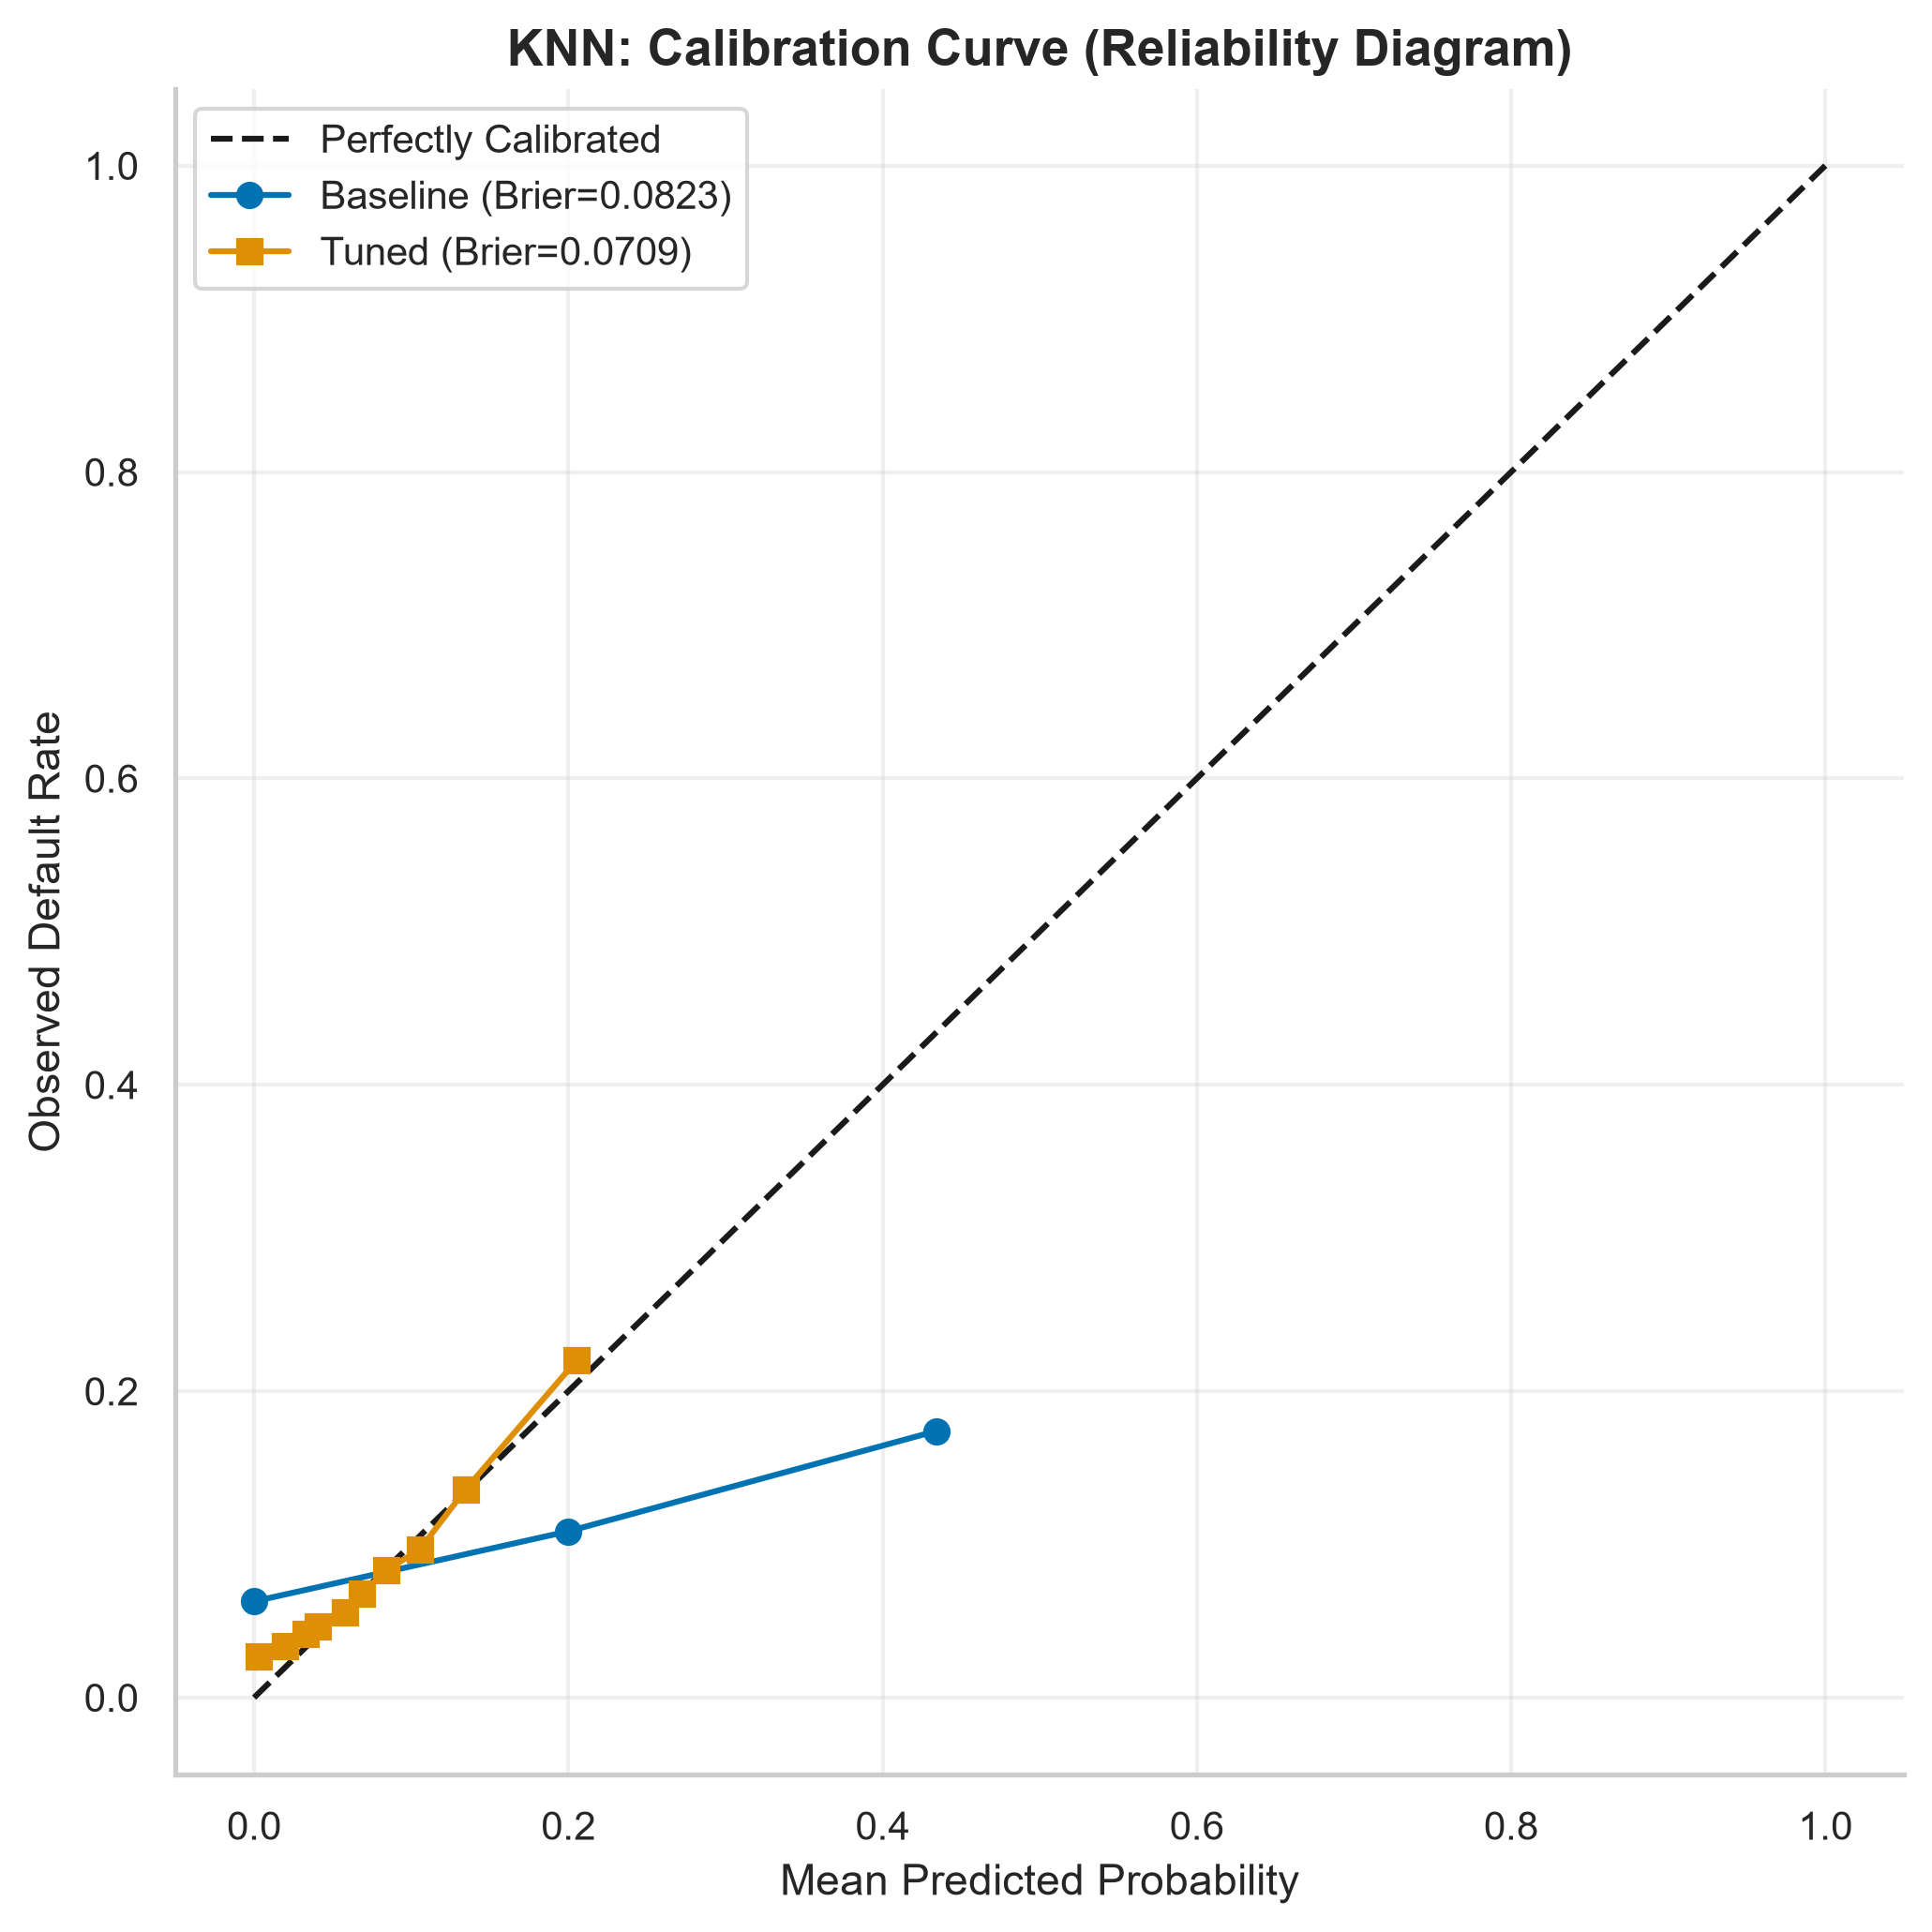

Brier Score - Baseline : 0.0823
Brier Score - Tuned    : 0.0709  (lower is better; 0 = perfect)


Fitting calibrated variants:   0%|          | 0/2 [00:00<?, ?it/s]

Brier Score - Sigmoid   : 0.0712


Brier Score - Isotonic  : 0.0712

Best calibration approach: tuned_uncalibrated (Brier = 0.0709)
Tuned model was already best-calibrated on Brier score; no separate calibrated model saved.


,Brier Score
tuned_uncalibrated,0.070906
sigmoid,0.071224
isotonic,0.071210


In [14]:
# ============================================================
# Calibration Curve, Brier Score & CalibratedClassifierCV
# ============================================================

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss
from tqdm.auto import tqdm

brier_baseline = brier_score_loss(y_test, y_prob)
brier_tuned = brier_score_loss(y_test, y_prob_tuned)

frac_pos_baseline, mean_pred_baseline = calibration_curve(y_test, y_prob, n_bins=10, strategy="quantile")
frac_pos_tuned, mean_pred_tuned = calibration_curve(y_test, y_prob_tuned, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(7, 7))
ax.plot([0, 1], [0, 1], "k--", label="Perfectly Calibrated")
ax.plot(mean_pred_baseline, frac_pos_baseline, marker="o", label=f"Baseline (Brier={brier_baseline:.4f})")
ax.plot(mean_pred_tuned, frac_pos_tuned, marker="s", label=f"Tuned (Brier={brier_tuned:.4f})")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Default Rate")
ax.set_title("KNN: Calibration Curve (Reliability Diagram)")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "08_knn_calibration_curve")
plt.show()

print(f"Brier Score - Baseline : {brier_baseline:.4f}")
print(f"Brier Score - Tuned    : {brier_tuned:.4f}  (lower is better; 0 = perfect)")

# CalibratedClassifierCV is fit on the same 40,000-row stratified subsample used for
# tuning, since KNN calibration folds are as expensive as the original search.
calibration_results = {"tuned_uncalibrated": brier_tuned}
calibrated_models = {}

for method in tqdm(["sigmoid", "isotonic"], desc="Fitting calibrated variants"):
    calibrated = CalibratedClassifierCV(
        estimator=KNeighborsClassifier(n_jobs=-1, **grid_search.best_params_),
        method=method,
        cv=3,
    )
    calibrated.fit(X_train_sub, y_train_sub)
    prob_calibrated = calibrated.predict_proba(X_test)[:, 1]
    brier = brier_score_loss(y_test, prob_calibrated)
    calibration_results[method] = brier
    calibrated_models[method] = calibrated
    print(f"Brier Score - {method.capitalize():<10}: {brier:.4f}")

best_method = min(calibration_results, key=calibration_results.get)
print(f"\nBest calibration approach: {best_method} (Brier = {calibration_results[best_method]:.4f})")

if best_method in calibrated_models:
    joblib.dump(calibrated_models[best_method], MODEL_DIR / "knn_calibrated_model.pkl")
    print("Best-calibrated model saved to: ../models/knn_calibrated_model.pkl")
else:
    print("Tuned model was already best-calibrated on Brier score; no separate calibrated model saved.")

pd.Series(calibration_results, name="Brier Score").to_frame()

### Business Interpretation: Probability Calibration

KNN's `predict_proba` is just the vote fraction among the `k` neighbors, so it is
inherently coarse (only `k+1` possible probability values when `weights="uniform"`) —
recalibration cannot fix a fundamentally discretized probability scale, only smooth it
statistically. Given KNN's weak discrimination (Section 1), it should not be considered
a candidate for the production scoring model regardless of calibration results; this
section is retained for completeness and cross-model comparability in Notebook 15
rather than because KNN is a realistic deployment candidate.

## 3. Additional Evaluation Metrics

Figure saved to: ..\figures\08_knn_precision_recall_curve.png


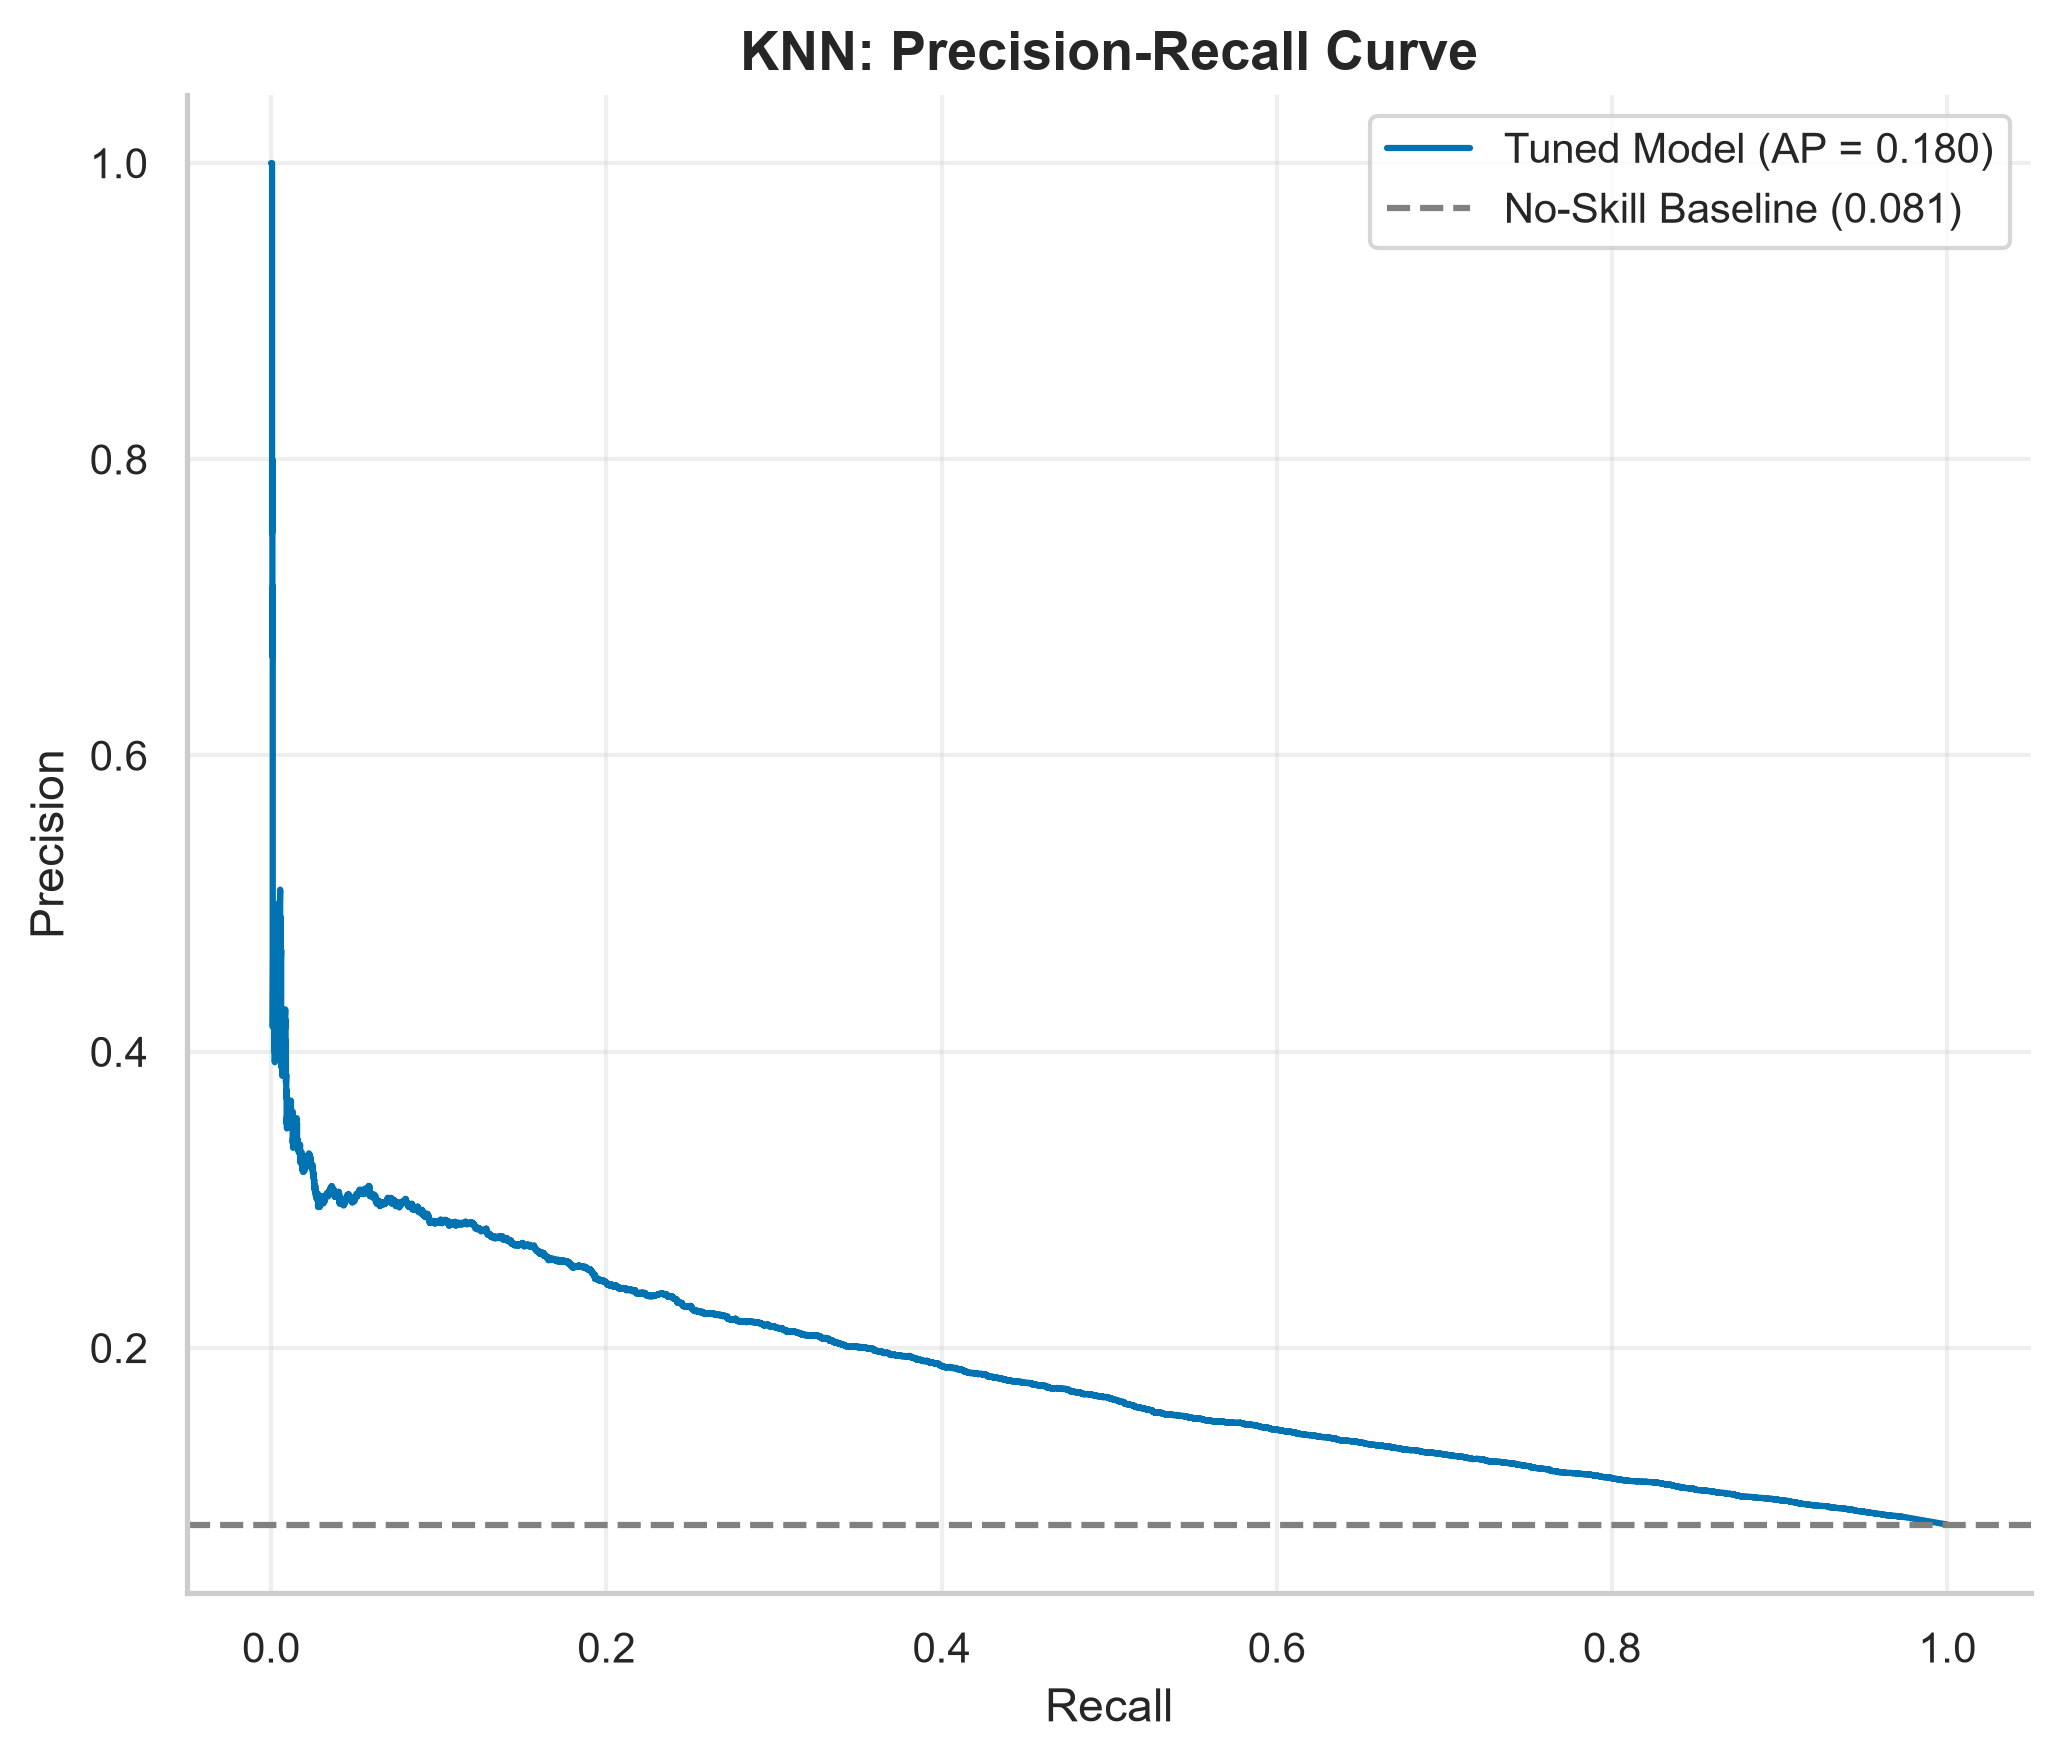

,Model,Variant,Accuracy,Precision,Recall,F1 Score,ROC AUC,MCC,Cohen's Kappa,Average Precision (PR-AUC),KS Statistic,Brier Score
0,K-Nearest Neighbors,Baseline,0.914329,0.244966,0.029406,0.052509,0.591036,0.059639,0.035824,0.108755,0.169094,0.082350
1,K-Nearest Neighbors,Tuned,0.919272,0.000000,0.000000,0.000000,0.695926,0.000000,0.000000,0.180096,0.290064,0.070906


In [15]:
# ============================================================
# Additional Evaluation Metrics: MCC, Kappa, PR-AUC, KS Statistic
# ============================================================

from sklearn.metrics import (
    matthews_corrcoef,
    cohen_kappa_score,
    precision_recall_curve,
    average_precision_score,
)

def extra_metrics(y_true, y_pred, y_prob):
    return {
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "Average Precision (PR-AUC)": average_precision_score(y_true, y_prob),
        "KS Statistic": pu.ks_statistic(y_true, y_prob),
        "Brier Score": brier_score_loss(y_true, y_prob),
    }

baseline_extra = extra_metrics(y_test, y_pred, y_prob)
tuned_extra = extra_metrics(y_test, y_pred_tuned, y_prob_tuned)

extended_row = pd.DataFrame([
    {"Model": "K-Nearest Neighbors", "Variant": "Baseline",
     "Accuracy": accuracy, "Precision": precision, "Recall": recall,
     "F1 Score": f1, "ROC AUC": auc, **baseline_extra},
    {"Model": "K-Nearest Neighbors", "Variant": "Tuned",
     "Accuracy": accuracy_tuned, "Precision": precision_tuned, "Recall": recall_tuned,
     "F1 Score": f1_tuned, "ROC AUC": auc_tuned, **tuned_extra},
])

pu.append_csv(OUTPUT_DIR / "model_results_extended.csv", extended_row)

precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_prob_tuned)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(recall_curve, precision_curve,
        label=f"Tuned Model (AP = {tuned_extra['Average Precision (PR-AUC)']:.3f})")
ax.axhline(y_test.mean(), color="gray", linestyle="--", label=f"No-Skill Baseline ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("KNN: Precision-Recall Curve")
ax.legend()
plt.tight_layout()
pu.save_fig(fig, "08_knn_precision_recall_curve")
plt.show()

extended_row

### Business Interpretation: Additional Metrics

Given an ROC-AUC around 0.59, MCC and Kappa for KNN are expected to be very close to
zero — i.e., statistically indistinguishable from a random or majority-class
classifier once class imbalance is accounted for. This is a useful negative result for
the paper: it demonstrates that not every "off-the-shelf" algorithm is suitable for
this problem, and justifies limiting deeper investment (extensive tuning, SHAP
explainability) to the models that show real discriminative signal.

**Note on Explainability:** SHAP is not applied to KNN in this project. `KernelExplainer`
(the only model-agnostic SHAP method applicable to KNN) is prohibitively slow at this
scale — its cost grows with both the number of explained instances and the size of the
background dataset, with no fast, exact alternative for instance-based models the way
`LinearExplainer` and `TreeExplainer` exist for linear and tree models. Given KNN's weak
predictive performance, this is a reasonable and explicitly documented scope limitation
rather than an oversight; it is listed as such in Notebook 15's Limitations section.